IRIS DATASET
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

 Logistic Regression
Accuracy: 93.33 %
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


 Decision Tree
Acc

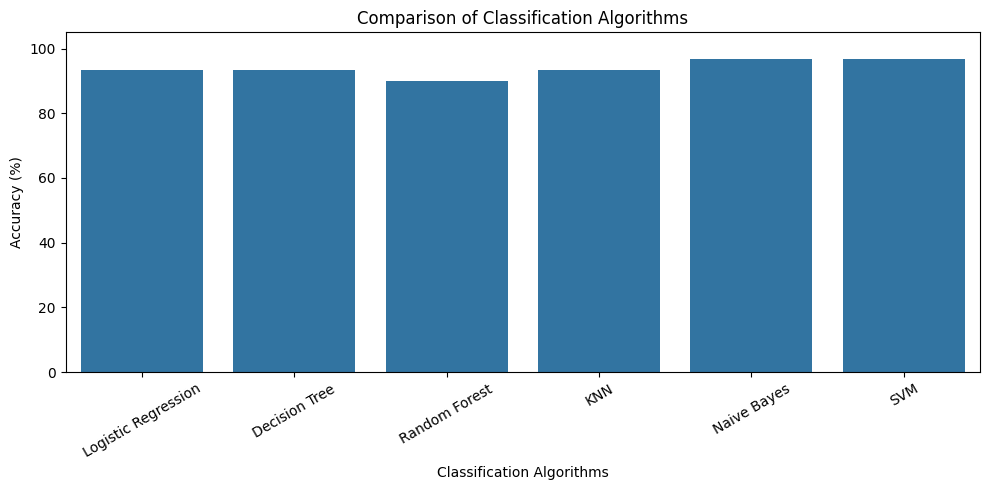

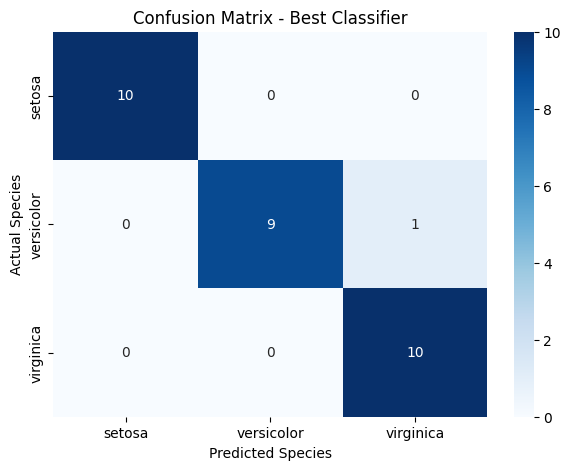


NEW FLOWER PREDICTION
Predicted Species: setosa


In [6]:

# COMPARISON OF CLASSIFICATION ALGORITHMS

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Step 2: Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df['Species'] = iris.target_names[y]

print("IRIS DATASET")
print(df.head())

# Step 3: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Define classification algorithms
models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'SVM': SVC()
}

# Step 6: Train and evaluate each algorithm
results = []

for name, model in models.items():

    # Use scaled data for distance-based and linear models
    if name in ['Logistic Regression', 'KNN', 'SVM']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average='weighted'
    )
    recall = recall_score(
        y_test, y_pred, average='weighted'
    )
    f1 = f1_score(
        y_test, y_pred, average='weighted'
    )

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy * 100,
        'Precision': precision * 100,
        'Recall': recall * 100,
        'F1 Score': f1 * 100
    })

    print("\n", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))

# Step 7: Display comparison table
results_df = pd.DataFrame(results)

print("\nCLASSIFICATION ALGORITHM COMPARISON")
print(results_df.round(2).to_string(index=False))

# Step 8: Find the best performing algorithm
best_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("\nBEST CLASSIFICATION ALGORITHM")
print("Algorithm:", best_model['Algorithm'])
print("Accuracy:", round(best_model['Accuracy'], 2), "%")

# Step 9: Visualize accuracy comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Accuracy'
)

plt.title("Comparison of Classification Algorithms")
plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=30)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

# Step 10: Confusion matrix for the best algorithm
best_name = best_model['Algorithm']
best_classifier = models[best_name]

if best_name in ['Logistic Regression', 'KNN', 'SVM']:
    best_classifier.fit(X_train_scaled, y_train)
    final_pred = best_classifier.predict(X_test_scaled)
else:
    best_classifier.fit(X_train, y_train)
    final_pred = best_classifier.predict(X_test)

cm = confusion_matrix(y_test, final_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - Best Classifier")
plt.show()

# Step 11: Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

if best_name in ['Logistic Regression', 'KNN', 'SVM']:
    new_flower_scaled = scaler.transform(new_flower)
    prediction = best_classifier.predict(new_flower_scaled)
else:
    prediction = best_classifier.predict(new_flower)

print("\nNEW FLOWER PREDICTION")
print("Predicted Species:",
      iris.target_names[prediction[0]])
